# 🚀 Practice Day 61

**📅 Date:** 2026-11-06  
📁 Category: Phase 2 · 테이블 병합(merge/join) (Round 5/5)

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Practice combining multiple related tables with merge() to answer questions no single table can answer alone
  (여러 개의 연관된 테이블을 merge()로 연결해서, 테이블 하나만으로는 풀 수 없는 질문에 답하는 연습)
- Find which instructor drives the most revenue, which class is booked most, and how average fee differs by class type
  (어떤 강사가 매출을 가장 많이 견인하는지, 어떤 클래스가 가장 많이 예약되는지, 클래스 유형별 평균 요금은 어떻게 다른지 파악하기)

---
# 📂 Dataset

**Dataset Name:** Lotus & Line Yoga Studio — Instructors, Classes & Bookings (3 tables) / Lotus & Line 요가 스튜디오 — 강사·클래스·예약 (3테이블)

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** Three related tables from a yoga studio. `instructors` (8 rows: instructor_id, instructor_name, specialty), `classes` (15 rows: class_id, class_name, instructor_id → links to instructors, class_type), and `bookings` (320 rows: booking_id, class_id → links to classes, booking_date, fee). Every class links to exactly one instructor, and every booking to exactly one class — clean, fully-linked keys with no missing values or duplicates. Fees are in USD.
(요가 스튜디오의 연관된 3개 테이블입니다. `instructors`(8명: instructor_id, instructor_name, specialty), `classes`(15개: class_id, class_name, instructor_id(instructors와 연결), class_type), `bookings`(320건: booking_id, class_id(classes와 연결), booking_date, fee). 모든 클래스는 강사 1명에게, 모든 예약은 클래스 1개에 연결되어 있고 결측치·중복 없이 깨끗합니다. 요금은 USD입니다.)

## Dataset Preview

In [22]:
# Dataset Preview
import pandas as pd
import numpy as np
from IPython.display import display

np.random.seed(42)
rng = np.random.default_rng(42)

# --- instructors ---
instructors_data = [
    ('Maya Lindqvist', 'Vinyasa'),
    ('Devon Okafor', 'Vinyasa'),
    ('Priya Raman', 'Hatha'),
    ('Sofia Marchetti', 'Pilates'),
    ('Kai Tanaka', 'Pilates'),
    ('Elena Vasquez', 'Restorative'),
    ('Marcus Reilly', 'Power Yoga'),
    ('Naomi Chen', 'Restorative'),
]
instructors = pd.DataFrame(instructors_data, columns=['instructor_name', 'specialty'])
instructors.insert(0, 'instructor_id', [f'I{str(i).zfill(2)}' for i in range(1, len(instructors) + 1)])

# --- classes ---
class_names_by_specialty = {
    'Vinyasa': ['Sunrise Flow', 'Power Flow'],
    'Hatha': ['Gentle Hatha', 'Morning Hatha'],
    'Pilates': ['Mat Pilates', 'Reformer Basics'],
    'Restorative': ['Deep Rest', 'Yin & Restore'],
    'Power Yoga': ['Power Hour'],
}
instr_by_spec = {}
for _, row in instructors.iterrows():
    instr_by_spec.setdefault(row['specialty'], []).append(row['instructor_id'])

class_rows = []
cid = 1
for spec, names in class_names_by_specialty.items():
    for name in names:
        for instr_id in instr_by_spec[spec]:
            class_rows.append({'class_id': f'C{str(cid).zfill(3)}', 'class_name': name,
                                'instructor_id': instr_id, 'class_type': spec})
            cid += 1
classes = pd.DataFrame(class_rows)
avg_price = {'Vinyasa': 28, 'Hatha': 22, 'Pilates': 32, 'Restorative': 20, 'Power Yoga': 30}  # USD per class

# --- bookings (some classes booked far more often than others) ---
n_bookings = 320
class_weight = rng.gamma(shape=2.0, scale=1.0, size=len(classes))
class_p = class_weight / class_weight.sum()
booking_class = rng.choice(classes['class_id'].values, size=n_bookings, replace=True, p=class_p)
booking_dates = pd.to_datetime('2024-01-01') + pd.to_timedelta(rng.integers(0, 200, size=n_bookings), unit='D')

class_type_map = dict(zip(classes['class_id'], classes['class_type']))
rows = []
for i in range(n_bookings):
    cid_ = booking_class[i]
    ct = class_type_map[cid_]
    noise = rng.normal(1.0, 0.06)
    fee = int(round(avg_price[ct] * noise))  # nearest USD
    rows.append({'booking_id': f'B{str(i+1).zfill(4)}', 'class_id': cid_, 'booking_date': booking_dates[i], 'fee': fee})
bookings = pd.DataFrame(rows).sort_values('booking_date').reset_index(drop=True)

print("Instructors:")
display(instructors)
print("\nClasses:")
display(classes.head())
print("\nBookings:")
display(bookings.head())


Instructors:


,instructor_id,instructor_name,specialty
0,I01,Maya Lindqvist,Vinyasa
1,I02,Devon Okafor,Vinyasa
2,I03,Priya Raman,Hatha
3,I04,Sofia Marchetti,Pilates
4,I05,Kai Tanaka,Pilates
5,I06,Elena Vasquez,Restorative
6,I07,Marcus Reilly,Power Yoga
7,I08,Naomi Chen,Restorative



Classes:


,class_id,class_name,instructor_id,class_type
0,C001,Sunrise Flow,I01,Vinyasa
1,C002,Sunrise Flow,I02,Vinyasa
2,C003,Power Flow,I01,Vinyasa
3,C004,Power Flow,I02,Vinyasa
4,C005,Gentle Hatha,I03,Hatha



Bookings:


,booking_id,class_id,booking_date,fee
0,B0065,C002,2024-01-01,26
1,B0193,C001,2024-01-01,27
2,B0137,C005,2024-01-02,19
3,B0138,C008,2024-01-02,35
4,B0082,C013,2024-01-03,20


## Dataset Information

In [23]:
# Dataset Information
print("Instructors:", instructors.shape)
instructors.info()
print("\nClasses:", classes.shape)
classes.info()
print("\nBookings:", bookings.shape)
bookings.info()

print("\n--- Describe: Instructors ---")
display(instructors.describe(include='all'))
print("\n--- Describe: Classes ---")
display(classes.describe(include='all'))
print("\n--- Describe: Bookings ---")
display(bookings.describe(include='all'))


Instructors: (8, 3)
<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   instructor_id    8 non-null      str  
 1   instructor_name  8 non-null      str  
 2   specialty        8 non-null      str  
dtypes: str(3)
memory usage: 324.0 bytes

Classes: (15, 4)
<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   class_id       15 non-null     str  
 1   class_name     15 non-null     str  
 2   instructor_id  15 non-null     str  
 3   class_type     15 non-null     str  
dtypes: str(4)
memory usage: 612.0 bytes

Bookings: (320, 4)
<class 'pandas.DataFrame'>
RangeIndex: 320 entries, 0 to 319
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   booking_id

,instructor_id,instructor_name,specialty
count,8,8,8
unique,8,8,5
top,I01,Maya Lindqvist,Vinyasa
freq,1,1,2



--- Describe: Classes ---


,class_id,class_name,instructor_id,class_type
count,15,15,15,15
unique,15,9,8,5
top,C001,Sunrise Flow,I01,Vinyasa
freq,1,2,2,4



--- Describe: Bookings ---


,booking_id,class_id,booking_date,fee
count,320,320,320,320.000000
unique,320,15,NaN,NaN
top,B0065,C002,NaN,NaN
freq,1,39,NaN,NaN
mean,NaN,NaN,2024-04-09 13:39:00,25.940625
min,NaN,NaN,2024-01-01 00:00:00,16.000000
25%,NaN,NaN,2024-02-18 18:00:00,21.000000
50%,NaN,NaN,2024-04-13 00:00:00,26.000000
75%,NaN,NaN,2024-05-29 00:00:00,30.000000
max,NaN,NaN,2024-07-18 00:00:00,35.000000


---
# ❓ Business Questions

1. **(Analysis)** Which instructor generated the most total revenue, and which the least?
   (어떤 강사가 총매출을 가장 많이/적게 냈는가?)
2. **(Analysis)** Which class has been booked the most times?
   (가장 많이 예약된 클래스는?)
3. **(Analysis)** Which class type has the highest average fee, and which the lowest?
   (평균 요금이 가장 높은/낮은 클래스 유형은?)
4. **(Visualization)** Compare total revenue across all instructors.
   (강사별 총매출을 비교하면?)
5. **(Visualization)** Compare total revenue across all class types.
   (클래스 유형별 총매출을 비교하면?)

---
# 🔍 Data Cleaning Check


In [24]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("===== instructors =====")
print("Missing values")
print(instructors.isnull().sum())
print("\nDuplicate rows:", instructors.duplicated().sum())
print("\nDtypes")
print(instructors.dtypes)
print("\nColumn names")
print(instructors.columns.tolist())
obj_cols = instructors.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(instructors[obj_cols].nunique())
print()

print("===== classes =====")
print("Missing values")
print(classes.isnull().sum())
print("\nDuplicate rows:", classes.duplicated().sum())
print("\nDtypes")
print(classes.dtypes)
print("\nColumn names")
print(classes.columns.tolist())
obj_cols = classes.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(classes[obj_cols].nunique())
print()

print("===== bookings =====")
print("Missing values")
print(bookings.isnull().sum())
print("\nDuplicate rows:", bookings.duplicated().sum())
print("\nDtypes")
print(bookings.dtypes)
print("\nColumn names")
print(bookings.columns.tolist())
obj_cols = bookings.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(bookings[obj_cols].nunique())
print()


===== instructors =====
Missing values
instructor_id      0
instructor_name    0
specialty          0
dtype: int64

Duplicate rows: 0

Dtypes
instructor_id      str
instructor_name    str
specialty          str
dtype: object

Column names
['instructor_id', 'instructor_name', 'specialty']

Text columns — unique counts
instructor_id      8
instructor_name    8
specialty          5
dtype: int64

===== classes =====
Missing values
class_id         0
class_name       0
instructor_id    0
class_type       0
dtype: int64

Duplicate rows: 0

Dtypes
class_id         str
class_name       str
instructor_id    str
class_type       str
dtype: object

Column names
['class_id', 'class_name', 'instructor_id', 'class_type']

Text columns — unique counts
class_id         15
class_name        9
instructor_id     8
class_type        5
dtype: int64

===== bookings =====
Missing values
booking_id      0
class_id        0
booking_date    0
fee             0
dtype: int64

Duplicate rows: 0

Dtypes
booking_id 

---
# 📊 Analysis

## Question 1

**Question:** Which instructor generated the most total revenue, and which the least? (총매출 최고·최저 강사는?)

**Result:**  
Sofia Marchetti generated the most revenue at **$1,690**, and Marcus Reilly the least at **$119**.  
(Sofia Marchetti가 **$1,690**으로 매출이 가장 높고, Marcus Reilly가 **$119**로 가장 낮습니다.)  

**Insight:**  
Sofia Marchetti earned **$1,571** more than Marcus Reilly, and Devon Okafor is second at **$1,446**.  
(Sofia Marchetti는 Marcus Reilly보다 **$1,571** 더 벌었고, 2위는 Devon Okafor로 **$1,446**입니다.)

In [25]:
# Question 1: total revenue by instructor - needs merging bookings with classes and instructors
merge_class = pd.merge(instructors, classes, on='instructor_id', how='left')
merge_df = pd.merge(merge_class, bookings, on='class_id', how='left')

total_revenue_by_instructor = merge_df.groupby('instructor_name')['fee'].sum().sort_values(ascending=False)

total_revenue_by_instructor

instructor_name
Sofia Marchetti    1690
Devon Okafor       1446
Kai Tanaka         1251
Elena Vasquez      1153
Maya Lindqvist     1010
Priya Raman         967
Naomi Chen          665
Marcus Reilly       119
Name: fee, dtype: int64

## Question 2

**Question:** Which class has been booked the most times? (가장 많이 예약된 클래스는?)

**Result:**  
Class C002 has been booked the most with **39** bookings, followed by C011 with **35**.  
(클래스 C002가 **39**건으로 가장 많이 예약되었고, C011이 **35**건으로 뒤를 잇습니다.)  

**Insight:**  
C002 has **4** more bookings than C011, and C005 and C009 are tied at **30**.  
(C002는 C011보다 **4**건 많고, C005와 C009는 **30**건으로 같습니다.)

In [26]:
# Question 2: which class has been booked the most - needs merging bookings with classes
merge_df.groupby('class_id')['booking_id'].count().sort_values(ascending=False).head(5)

class_id
C002    39
C011    35
C005    30
C009    30
C007    23
Name: booking_id, dtype: int64

In [30]:
class_counts = merge_df.groupby('class_id')['booking_id'].count().sort_values(ascending=False)
top_class_id = class_counts.index[0]

merge_df[merge_df['class_id'] == top_class_id].head(3)

,instructor_id,instructor_name,specialty,class_id,class_name,class_type,booking_id,booking_date,fee
37,I02,Devon Okafor,Vinyasa,C002,Sunrise Flow,Vinyasa,B0065,2024-01-01,26
38,I02,Devon Okafor,Vinyasa,C002,Sunrise Flow,Vinyasa,B0173,2024-01-18,25
39,I02,Devon Okafor,Vinyasa,C002,Sunrise Flow,Vinyasa,B0183,2024-01-20,29


## Question 3

**Question:** Which class type has the highest average fee, and which the lowest? (평균 요금 최고·최저 클래스 유형은?)

**Result:**  
Pilates has the highest average fee at **$31.97**, and Restorative the lowest at **$19.76**.  
(Pilates의 평균 요금이 **$31.97**로 가장 높고, Restorative가 **$19.76**으로 가장 낮습니다.)  

**Insight:**  
The gap between Pilates and Restorative is **$12.21** per booking.  
(Pilates와 Restorative의 차이는 예약당 **$12.21**입니다.)

In [28]:
# Question 3: average fee by class_type
merge_df.groupby('class_type')['fee'].mean().sort_values(ascending=False).round(2)

class_type
Pilates        31.97
Power Yoga     29.75
Vinyasa        27.60
Hatha          22.49
Restorative    19.76
Name: fee, dtype: float64

---
# 📈 Visualization

**Chart 1:** Bar chart — total revenue by instructor (막대그래프: 강사별 총매출)

*Interpretation:*  
Sofia Marchetti has the longest bar at **$1,690**, and Marcus Reilly the shortest at **$119**.  
(Sofia Marchetti 막대가 **$1,690**으로 가장 길고 Marcus Reilly가 **$119**로 가장 짧습니다.)  

---

**Chart 2:** Bar chart — total revenue by class type (막대그래프: 클래스 유형별 총매출)

*Interpretation:*  
Pilates has the highest total at **$2,941** and Power Yoga the lowest at **$119**. Vinyasa is second at **$2,456**.  
(Pilates의 총매출이 **$2,941**로 가장 높고 Power Yoga가 **$119**로 가장 낮습니다. Vinyasa는 **$2,456**으로 두 번째입니다.)


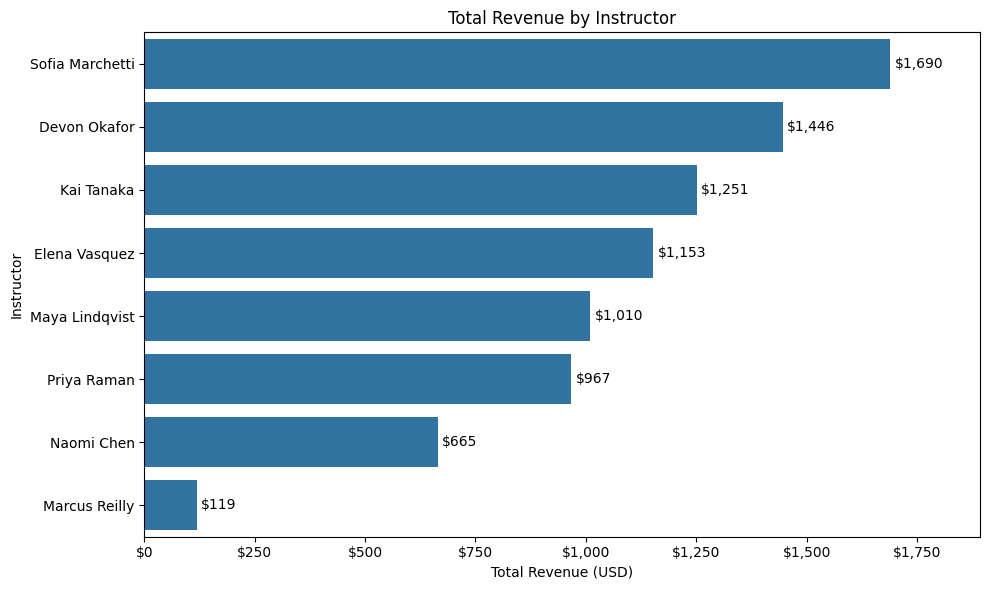

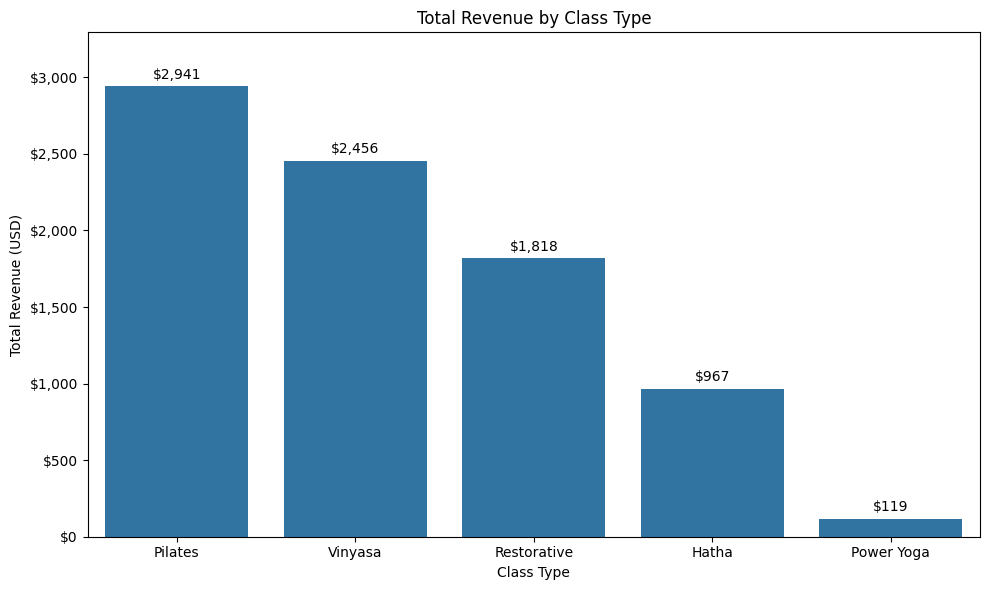

In [29]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Chart 1: total revenue by instructor (bar), same order as the Q1 table
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=total_revenue_by_instructor.values, y=total_revenue_by_instructor.index, ax=ax, errorbar=None)
ax.set_title('Total Revenue by Instructor')
ax.set_xlabel('Total Revenue (USD)')
ax.set_ylabel('Instructor')
ax.xaxis.set_major_formatter('${x:,.0f}')
ax.bar_label(ax.containers[0], fmt='${:,.0f}', padding=3)
ax.margins(x=0.12)
plt.tight_layout()
plt.show()

# Chart 2: total revenue by class_type (bar), highest total first
revenue_by_class_type = merge_df.groupby('class_type')['fee'].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=revenue_by_class_type.index, y=revenue_by_class_type.values, ax=ax, errorbar=None)
ax.set_title('Total Revenue by Class Type')
ax.set_xlabel('Class Type')
ax.set_ylabel('Total Revenue (USD)')
ax.yaxis.set_major_formatter('${x:,.0f}')
ax.bar_label(ax.containers[0], fmt='${:,.0f}', padding=3)
ax.margins(y=0.12)
plt.tight_layout()
plt.show()


---
# 💼 Business Insights
*What did I discover?*

- Sofia Marchetti is the top instructor at **$1,690**, and Marcus Reilly is the lowest at **$119**.  
  (Sofia Marchetti가 **$1,690**으로 매출 1위 강사이고, Marcus Reilly가 **$119**로 가장 낮습니다.)  
- Class C002 is booked the most at **39** bookings.  
  (클래스 C002가 **39**건으로 가장 많이 예약됩니다.)  
- Power Yoga has the second-highest average fee (**$29.75**) but the lowest total revenue (**$119**).  
  (Power Yoga는 평균 요금이 두 번째로 높은데(**$29.75**) 총매출은 가장 낮습니다(**$119**).)  


---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Review Marcus Reilly's classes, since the revenue is only **$119** against **$1,690** for the top instructor.  
   (최고 강사의 **$1,690**에 비해 매출이 **$119**뿐인 Marcus Reilly의 클래스를 살펴봅니다.)  
2. Look into why Power Yoga has a high average fee (**$29.75**) but few bookings behind its **$119**.  
   (Power Yoga의 평균 요금은 높은데(**$29.75**) 총매출이 **$119**에 그치는 이유를 살펴봅니다.)  
3. Check what makes C002 draw **39** bookings, and try it on the classes with fewer.  
   (C002가 **39**건을 모으는 이유를 확인하고, 예약이 적은 클래스에 적용해 봅니다.)  


---
# ✅ What I Learned
*Today's biggest lesson*

- Merge instructors, classes, and bookings in two steps to link every booking to its instructor.  
  (instructors, classes, bookings를 두 단계로 병합하면 모든 예약이 강사와 연결됩니다.)  
- Filter the merged table with a boolean condition such as `merge_df['class_id'] == top_class_id` to see all rows of one class.  
  (`merge_df['class_id'] == top_class_id` 같은 조건으로 병합 표를 걸러 한 클래스의 모든 행을 봅니다.)  
-   


---
# 🧠 Reflection

**What was difficult?**  
Seeing every row of the most booked class instead of stopping at the top five counts.  
(상위 5개 건수에서 멈추지 않고 가장 많이 예약된 클래스의 모든 행을 보는 것)

**Why?**  
`groupby(...).count().head(5)` returns only the counts, not the booking rows.  
(`groupby(...).count().head(5)`는 건수만 돌려주고 예약 행은 주지 않음)

**How did I solve it?**  
Saved the top `class_id` from the sorted counts and filtered `merge_df` with `merge_df['class_id'] == top_class_id`.  
(정렬한 건수에서 첫 `class_id`를 저장하고 `merge_df['class_id'] == top_class_id`로 걸러 냄)

**What would I do differently next time?**  
Group by `class_name` together with `class_id` so the answer shows a name.  
(답에 이름이 보이도록 `class_id`와 함께 `class_name`으로도 묶기)


---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★★☆☆  
I can merge three tables and answer questions from the merged table.  
(3개 테이블을 병합하고 병합 표에서 질문에 답할 수 있습니다.)  

**Confidence**  
★★★★★★★☆☆☆  

**Difficulty**  
★★★★☆☆☆☆☆☆  


---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Day 62: SQL intermediate  
  (Day 62: SQL 중급)  
